# k-NN + NN Voting V1

For this experiment, I wanted to see if combining k-NN and some of our neural networks would improve the predictions. I compared the models on the same validation examples and tried majority voting for images.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from collections import Counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.dont_write_bytecode = True
sys.path.insert(0, str(ROOT))
from src.data_loader import split_train_val

OUT = ROOT / 'results/model_comparison'
OUT.mkdir(parents=True, exist_ok=True)
CANDIDATE = ROOT / 'submissions/submission_knn_nn_voting_v1.csv'
source_paths = [ROOT / 'submission/knn/submission_final_knn.csv']
source_paths += [ROOT / f'submission/nn/submission_v{version}_nn.csv' for version in (2, 3, 4)]

def save_table(frame, path):
    if path.exists():
        pd.testing.assert_frame_equal(pd.read_csv(path), frame, check_dtype=False,
                                      check_exact=False, rtol=1e-14, atol=1e-14)
    else:
        frame.to_csv(path, index=False)

I loaded the saved validation predictions and checked that the indices and true labels matched the seed 42 split. Then I compared the individual model accuracies.

In [2]:
frames = {'image': {}, 'sentiment': {}}
rows = []
for task, count, maximum in [('image', 4000, 49), ('sentiment', 2400, 2)]:
    raw_labels = pd.read_csv(ROOT / f'data/raw/{task}_train.csv', usecols=['label']).label.to_numpy()
    positions = np.arange(len(raw_labels)).reshape(-1, 1)
    train_positions, val_positions, train_labels, true_labels = split_train_val(
        positions, raw_labels, val_fraction=0.2, seed=42)
    assert len(true_labels) == count
    print(task, 'raw training rows:', len(raw_labels), 'split training rows:', len(train_labels),
          'validation rows:', len(true_labels))
    names = ['knn_v8', 'nn_v2', 'nn_v3', 'nn_v4', 'nn_v8', 'nn_v9'] if task == 'image' else [
        'nn_v1', 'nn_v2', 'nn_v3', 'nn_v4', 'knn_v9', 'nn_v8']
    paths = [(name, ROOT / f'results/{task}/{name}_validation.csv') for name in names]
    paths += [(name + '_v5', ROOT / f'results/{name}/{name}_v5_{task}_validation.csv')
              for name in ['decision_tree', 'random_forest']]
    for name, p in paths:
        f = pd.read_csv(p)
        assert {'validation_index', 'actual_label', 'predicted_label'}.issubset(f.columns)
        assert len(f) == count and f.validation_index.is_unique
        assert pd.api.types.is_integer_dtype(f.validation_index)
        assert np.array_equal(f.validation_index, np.arange(count))
        for column in ['actual_label', 'predicted_label']:
            assert pd.api.types.is_integer_dtype(f[column])
            assert f[column].between(0, maximum).all() and not f[column].isna().any()
        assert np.array_equal(f.actual_label, true_labels), str(p)
        frames[task][name] = f
        correct = int((f.actual_label == f.predicted_label).sum())
        rows.append({'task': task, 'model': name, 'accuracy': correct / count,
                     'correct_count': correct, 'count': count, 'source': p.relative_to(ROOT).as_posix()})
comparison = pd.DataFrame(rows)
save_table(comparison, OUT / 'model_validation_comparison.csv')
print(comparison.to_string(index=False))


image raw training rows: 20000 split training rows: 16000 validation rows: 4000


sentiment raw training rows: 12000 split training rows: 9600 validation rows: 2400
     task            model  accuracy  correct_count  count                                                          source
    image           knn_v8  0.396250           1585   4000                             results/image/knn_v8_validation.csv
    image            nn_v2  0.337750           1351   4000                              results/image/nn_v2_validation.csv
    image            nn_v3  0.338000           1352   4000                              results/image/nn_v3_validation.csv
    image            nn_v4  0.388750           1555   4000                              results/image/nn_v4_validation.csv
    image            nn_v8  0.295250           1181   4000                              results/image/nn_v8_validation.csv
    image            nn_v9  0.388750           1555   4000                              results/image/nn_v9_validation.csv
    image decision_tree_v5  0.041000            164   40

I tried majority voting for images. If labels tied for the most votes, I used k-NN first, followed by NN V4, NN V3 and NN V2.

In [3]:
def vote(prediction_lists, priority_positions):
    if not prediction_lists or len({len(p) for p in prediction_lists}) != 1:
        raise ValueError('Prediction sequences must have identical lengths')
    if sorted(priority_positions) != list(range(len(prediction_lists))):
        raise ValueError('Priority must contain every model position once')
    result = []
    for labels in zip(*prediction_lists):
        counts = Counter(labels)
        maximum = max(counts.values())
        leaders = {label for label, count in counts.items() if count == maximum}
        for position in priority_positions:
            if labels[position] in leaders:
                result.append(int(labels[position]))
                break
    return np.array(result, dtype=int)

models = ['knn', 'nn_v2', 'nn_v3', 'nn_v4']
priority = [0, 3, 2, 1]
for labels, expected in [([4, 7, 7, 9], 7), ([4, 4, 6, 6], 4),
                         ([1, 2, 3, 4], 1), ([1, 2, 3, 3], 3),
                         ([4, 7, 7, 7], 7), ([8, 8, 8, 8], 8)]:
    assert vote([[label] for label in labels], priority).tolist() == [expected]

I compared the three-model and four-model votes with k-NN and NN V4. I also counted where the four-model vote helped or hurt compared with k-NN.

In [4]:
image = frames['image']
validation_names = ['knn_v8' if name == 'knn' else name for name in models]
image_lists = [image[name].predicted_label.to_numpy() for name in validation_names]
image_truth = image['knn_v8'].actual_label.to_numpy()
image_candidates = {
    'k-NN V8': image_lists[0],
    'NN V4': image_lists[3],
    'k-NN + NN V3 + NN V4': vote([image_lists[i] for i in [0, 2, 3]], [0, 2, 1]),
    'k-NN + NN V2 + NN V3 + NN V4': vote(image_lists, priority),
}
image_trials = pd.DataFrame([
    {'candidate': name, 'correct_count': int((pred == image_truth).sum()),
     'count': len(pred), 'accuracy': float((pred == image_truth).mean())}
    for name, pred in image_candidates.items()])
save_table(image_trials, OUT / 'image_vote_trials.csv')
image_vote = image_candidates['k-NN + NN V2 + NN V3 + NN V4']
knn_correct = image_lists[0] == image_truth
vote_correct = image_vote == image_truth
fixed = int((~knn_correct & vote_correct).sum())
broken = int((knn_correct & ~vote_correct).sum())
assert int(vote_correct.sum() - knn_correct.sum()) == fixed - broken
voted_validation = pd.DataFrame({'validation_index': np.arange(4000), 'actual_label': image_truth,
    'predicted_label': image_vote, 'knn_label': image_lists[0], 'nn_v2_label': image_lists[1],
    'nn_v3_label': image_lists[2], 'nn_v4_label': image_lists[3]})
save_table(voted_validation, OUT / 'image_voted_validation.csv')
print(image_trials.to_string(index=False))
print('Newly correct:', fixed, 'previously correct made wrong:', broken, 'net gain:', fixed - broken)

                   candidate  correct_count  count  accuracy
                     k-NN V8           1585   4000   0.39625
                       NN V4           1555   4000   0.38875
        k-NN + NN V3 + NN V4           1722   4000   0.43050
k-NN + NN V2 + NN V3 + NN V4           1763   4000   0.44075
Newly correct: 493 previously correct made wrong: 315 net gain: 178


I also compared the first and second halves of the image validation set. These are two parts of the same validation set, not separate held-out tests.

In [5]:
halves = []
for start, end in [(0, 2000), (2000, 4000)]:
    for name, pred in [('k-NN V8', image_lists[0]), ('Four-way vote', image_vote)]:
        correct = int((pred[start:end] == image_truth[start:end]).sum())
        halves.append({'positions': f'{start}..{end-1}', 'candidate': name,
                       'correct_count': correct, 'count': end-start, 'accuracy': correct/(end-start)})
halves = pd.DataFrame(halves)
save_table(halves, OUT / 'image_vote_halves.csv')
print(halves.to_string(index=False))

 positions     candidate  correct_count  count  accuracy
   0..1999       k-NN V8            778   2000    0.3890
   0..1999 Four-way vote            865   2000    0.4325
2000..3999       k-NN V8            807   2000    0.4035
2000..3999 Four-way vote            898   2000    0.4490


For sentiment, I compared NN V3 with a three-network vote. I kept NN V3 for the combined submission since it had the strongest individual validation accuracy.

In [6]:
sentiment = frames['sentiment']
sentiment_truth = sentiment['nn_v3'].actual_label.to_numpy()
sentiment_main = sentiment['nn_v3'].predicted_label.to_numpy()
sentiment_vote = vote([sentiment[name].predicted_label.to_numpy()
                       for name in ['nn_v1', 'nn_v3', 'nn_v4']], [1, 2, 0])
sentiment_trials = pd.DataFrame([
    {'candidate': name, 'correct_count': int((pred == sentiment_truth).sum()),
     'count': len(pred), 'accuracy': float((pred == sentiment_truth).mean()), 'role': role}
    for name, pred, role in [('NN V3', sentiment_main, 'primary'),
                           ('NN V1 + NN V3 + NN V4', sentiment_vote, 'exploratory only')]])
save_table(sentiment_trials, OUT / 'sentiment_vote_trials.csv')
sentiment_accuracy = float((sentiment_main == sentiment_truth).mean())
voting_comparison = pd.DataFrame([
    {'candidate': name, 'image_accuracy': float((pred == image_truth).mean()),
     'sentiment_accuracy': sentiment_accuracy,
     'combined_accuracy': (float((pred == image_truth).mean()) + sentiment_accuracy) / 2}
    for name, pred in [('Previous k-NN image + NN V3 sentiment', image_lists[0]),
                       ('Four-way image vote + NN V3 sentiment', image_vote)]])
save_table(voting_comparison, OUT / 'voting_v1_validation_comparison.csv')
print(sentiment_trials.to_string(index=False))
print(voting_comparison.to_string(index=False))
print('Combined accuracy is the equal task average, not the 6400-row micro-average.')

            candidate  correct_count  count  accuracy             role
                NN V3           1639   2400  0.682917          primary
NN V1 + NN V3 + NN V4           1643   2400  0.684583 exploratory only
                            candidate  image_accuracy  sentiment_accuracy  combined_accuracy
Previous k-NN image + NN V3 sentiment         0.39625            0.682917           0.539583
Four-way image vote + NN V3 sentiment         0.44075            0.682917           0.561833
Combined accuracy is the equal task average, not the 6400-row micro-average.


I plotted the accuracies to compare the results.

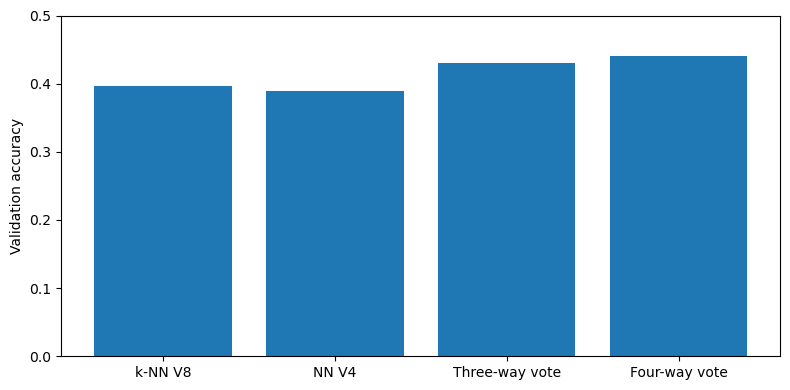

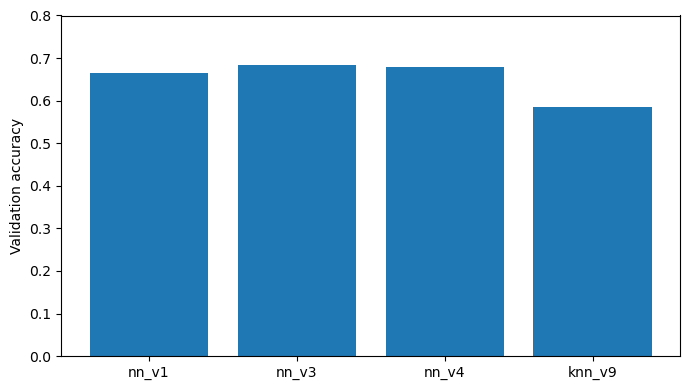

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(['k-NN V8', 'NN V4', 'Three-way vote', 'Four-way vote'], image_trials.accuracy)
ax.set_ylabel('Validation accuracy')
ax.set_ylim(0, 0.5)
fig.tight_layout()
if not (OUT / 'image_vote_accuracy.png').exists():
    fig.savefig(OUT / 'image_vote_accuracy.png', dpi=150)
plt.show()

sentiment_plot = comparison[(comparison.task == 'sentiment') &
                            comparison.model.isin(['nn_v1', 'nn_v3', 'nn_v4', 'knn_v9'])]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(sentiment_plot.model, sentiment_plot.accuracy)
ax.set_ylabel('Validation accuracy')
ax.set_ylim(0, 0.8)
fig.tight_layout()
if not (OUT / 'sentiment_model_accuracy.png').exists():
    fig.savefig(OUT / 'sentiment_model_accuracy.png', dpi=150)
plt.show()

Finally, I combined the image and sentiment predictions into one submission file. I matched each source by ID and compared Voting V1 with k-NN image and NN V3 sentiment.

In [8]:
sample = pd.read_csv(ROOT / 'data/raw/sample_submission.csv')
assert sample.columns.tolist() == ['id', 'label']
assert len(sample) == 10000 and sample.id.is_unique and not sample.id.isna().any()
image_ids = pd.read_csv(ROOT / 'data/raw/image_test.csv', usecols=['id']).id
text_ids = pd.read_csv(ROOT / 'data/raw/sentiment_test.csv', usecols=['id']).id
assert len(image_ids) == len(text_ids) == 5000
assert image_ids.is_unique and text_ids.is_unique
assert image_ids.str.startswith('img_').all() and text_ids.str.startswith('text_').all()
assert set(image_ids).isdisjoint(set(text_ids))
assert set(sample.id) == set(image_ids) | set(text_ids)
is_image = sample.id.str.startswith('img_').to_numpy()
is_text = sample.id.str.startswith('text_').to_numpy()
assert is_image.sum() == is_text.sum() == 5000
assert (is_image | is_text).all()

def check_submission(frame):
    assert frame.columns.tolist() == ['id', 'label']
    assert len(frame) == 10000 and frame.id.is_unique and not frame.isna().any().any()
    assert set(frame.id) == set(sample.id)
    assert pd.api.types.is_integer_dtype(frame.label)
    assert frame.loc[frame.id.str.startswith('img_'), 'label'].between(0, 49).all()
    assert frame.loc[frame.id.str.startswith('text_'), 'label'].between(0, 2).all()

aligned = []
for p in source_paths:
    source = pd.read_csv(p)
    check_submission(source)
    merged = sample[['id']].merge(source, on='id', how='left', sort=False, validate='one_to_one')
    assert merged.id.tolist() == sample.id.tolist()
    check_submission(merged)
    aligned.append(merged.label.to_numpy())

output = sample[['id']].copy()
labels = aligned[2].copy()
labels[is_image] = vote([p[is_image] for p in aligned], priority)
output['label'] = labels
check_submission(output)
assert output.id.tolist() == sample.id.tolist()
assert np.array_equal(output.label.to_numpy()[is_text], aligned[2][is_text])
baseline_labels = aligned[2].copy()
baseline_labels[is_image] = aligned[0][is_image]
changed = output.label.to_numpy() != baseline_labels
print('Changed image labels:', int(changed[is_image].sum()))
print('Changed sentiment labels:', int(changed[is_text].sum()))
if CANDIDATE.exists():
    pd.testing.assert_frame_equal(pd.read_csv(CANDIDATE), output)
    print('Saved Voting V1 predictions match the calculated vote.')
else:
    output.to_csv(CANDIDATE, index=False)
    print('Created:', CANDIDATE.relative_to(ROOT))
saved = pd.read_csv(CANDIDATE)
pd.testing.assert_frame_equal(saved, output)
check_submission(saved)
print('10000 rows; 5000 per task; exact ID coverage and order; integer labels; valid ranges.')


Changed image labels: 1878
Changed sentiment labels: 0
Saved Voting V1 predictions match the calculated vote.
10000 rows; 5000 per task; exact ID coverage and order; integer labels; valid ranges.


I left NN V9 out of the image vote because its saved validation predictions match NN V4.

In [9]:
assert np.array_equal(image['nn_v9'].predicted_label, image['nn_v4'].predicted_label)
print('NN V9 and NN V4 have the same saved predictions on all 4000 image validation examples.')

NN V9 and NN V4 have the same saved predictions on all 4000 image validation examples.


The four-model image vote got 1763 of 4000 examples right, compared with 1585 for k-NN and 1722 for the three-model vote. It fixed 493 k-NN mistakes and made 315 previously correct predictions wrong, giving 178 more correct predictions. Accuracy improved in both validation halves.

NN V3 got 1639 of 2400 sentiment examples right. The sentiment vote got four more right, which is a small difference on this reused validation set, so I kept NN V3. The equal task average increased from 0.5395833333333333 to 0.5618333333333333. Voting V1 changes 1878 image predictions and no sentiment predictions compared with the k-NN image and NN V3 sentiment mix. These validation results do not guarantee a higher Kaggle score.